# 6. Решения

Правило зафиксировано в ноутбуке 02 до расчёта эффектов и применяется без изменений:
- выкатывать - значим после BH (21 тест основной выборки) и эффект больше нуля;
- не выкатывать - значим после BH и эффект меньше нуля, или незначим и верхняя граница бутстреп-интервала 95% ниже
  +3 п.п.;
- мало данных - незначим и интервал содержит +3 п.п.;
- 256027: если с 6 добавленными бросившими в C решение другое, пишу «мало данных»;
- 263057 в решения не входит.

Проверки устойчивости, триггерный анализ и вторичная метрика решение не меняют, они попадают только в пометки.
+3 п.п. - продуктовое допущение: прирост доли завершивших, ради которого стоит менять задание для всех учеников.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, db, effects, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)
con = db.connect()
TARGET = 0.03

In [2]:
# Тот же порядок расчётов, что в ноутбуке 03, чтобы бутстреп-интервалы совпали до цифры.
wide = effects.completion_wide(con)
groups = effects.trigger_table(con)
rng = np.random.default_rng(config.SEED)
main = effects.effects(wide[wide["sample"] == "all"], rng)
effects.effects(wide[(wide["sample"] == "experienced") & wide.experiment_id.isin(groups[groups.symmetric].experiment_id)], rng)
effects.effects(wide[wide["sample"] == "video_viewers"], rng)
adj = wide[(wide["sample"] == "all") & (wide.experiment_id == 256027)].copy()
adj["n_c"] += 6
sens = effects.effects(adj, rng).iloc[0]
names = db.run(con, "quality.sql", "per_experiment")[["experiment_id", "experiment_name"]]

In [3]:
def pp(x):
    return f"{100 * x:+.1f}".replace(".", ",")


def rule(diff, lo, hi, p_bh):
    if p_bh < 0.05:
        return "выкатывать" if diff > 0 else "не выкатывать"
    return "не выкатывать" if hi < TARGET else "мало данных"


t = main.copy()
dec_mask = t.experiment_id != effects.EXCLUDED
t.loc[dec_mask, "p_bh"] = stats.bh_adjust(t.loc[dec_mask, "p"])
t["decision"] = ""
t["rationale"] = ""
for i, r in t.iterrows():
    if r.experiment_id == effects.EXCLUDED:
        t.loc[i, ["decision", "rationale"]] = ["исключён", "группы несравнимы: в контроле, похоже, нет рано бросивших"]
        continue
    d = rule(r["diff"], r.boot_lo, r.boot_hi, r.p_bh)
    ci = f"интервал {pp(r.boot_lo)}...{pp(r.boot_hi)} п.п."
    if d == "не выкатывать" and r.p_bh >= 0.05:
        why = f"незначимо, {ci}: прирост +3 п.п. исключён"
    elif d == "мало данных":
        why = f"незначимо, {ci} включает +3 п.п."
    else:
        why = f"значимо после BH, {ci}"
    if r.experiment_id == 256027:
        d_sens = rule(sens["diff"], sens.boot_lo, sens.boot_hi, 1.0)
        if d_sens != d:
            why = (f"в файле {ci} (не выкатывать), с 6 добавленными бросившими в C интервал до "
                   f"{pp(sens.boot_hi)} п.п.: решение неустойчиво")
            d = "мало данных"
    t.loc[i, ["decision", "rationale"]] = [d, why]

Пометки: что не меняет решение, но важно для того, кто будет его читать. Все числа - из ноутбуков 03-05.

In [4]:
notes = {
    237447: "контроль 98,5%: расти некуда, условие немного снижает долю (p = 0,041 до поправки); у завершивших в E больше задач",
    241501: "у завершивших в E на 16% больше задач, значимо после BH во вторичном семействе",
    241622: "у завершивших в E на 14% больше задач, значимо после BH во вторичном семействе",
    256027: "в E 6 рано бросивших без пары в C",
    259379: "доли не видящих видео в группах различаются (p = 0,035); без них эффект -1,7 п.п. вместо -5,1",
    293151: "гипотеза для повторного теста: среди увидевших условие +8,4 п.п. (p = 0,040, после BH 0,49); "
            "нужно 378 увидевших в группе",
    377658: "контроль 97%: +3 п.п. невозможны",
    263057: "справочно: -4,7 п.п. на всех, +5,4 п.п. среди увидевших условие",
}
t["note"] = t.experiment_id.map(notes).fillna("")
table = names.merge(t, on="experiment_id")
table["n"] = table.n_c + table.n_e
table["effect_pp"] = (100 * table["diff"]).round(1)
table[["experiment_id", "experiment_name", "n", "effect_pp", "p", "p_bh", "decision", "rationale", "note"]].round(3)

,experiment_id,experiment_name,n,effect_pp,p,p_bh,decision,rationale,note
0,226210,Multiplying Mixed Numbers 5.NF.B.4a EX,1185,-4.5,0.099,0.721,не выкатывать,"незначимо, интервал -9,9...+0,9 п.п.: прирост +3 п.п. исключён",
1,237447,Understanding Vocabulary About Circles G-C.A.2 EX,692,-2.6,0.041,0.721,не выкатывать,"незначимо, интервал -5,1...-0,2 п.п.: прирост +3 п.п. исключён","контроль 98,5%: расти некуда, условие немного снижает долю (p = 0,041 до поправки); у завершивших в E больше задач"
2,241501,Equivalent Expressions 6.EE.B.4 EX,381,-4.4,0.201,0.766,не выкатывать,"незначимо, интервал -11,2...+2,4 п.п.: прирост +3 п.п. исключён","у завершивших в E на 16% больше задач, значимо после BH во вторичном семействе"
3,241622,Writing Inequalities from Situations 6.EE.B8 EX,627,-4.4,0.110,0.721,не выкатывать,"незначимо, интервал -9,9...+0,9 п.п.: прирост +3 п.п. исключён","у завершивших в E на 14% больше задач, значимо после BH во вторичном семействе"
4,243393,Dividing Mixed Numbers 6.NS.A.1-Ex,1797,-1.6,0.449,0.815,не выкатывать,"незначимо, интервал -5,7...+2,6 п.п.: прирост +3 п.п. исключён",
5,246482,Finding Expected Value SS.MD.B.5 EX,457,0.8,0.845,0.888,мало данных,"незначимо, интервал -7,1...+9,0 п.п. включает +3 п.п.",
6,246627,Conditional Probability SS-CP.A.3 EX,514,-3.0,0.449,0.815,мало данных,"незначимо, интервал -10,8...+5,1 п.п. включает +3 п.п.",
7,246647,Permutations and Combinations SS-CP.B.2 EX,538,0.2,0.948,0.948,мало данных,"незначимо, интервал -5,8...+6,5 п.п. включает +3 п.п.",
8,250476,Basic Logarithm Manipulation F-BF.B.5 EX,402,4.2,0.137,0.721,мало данных,"незначимо, интервал -1,4...+9,7 п.п. включает +3 п.п.",
9,255116,Properties of Exponents 8.EE.A.1 EX,534,-2.5,0.470,0.815,мало данных,"незначимо, интервал -9,2...+4,3 п.п. включает +3 п.п.",


In [5]:
table.decision.value_counts()

decision
мало данных      14
не выкатывать     7
исключён          1
Name: count, dtype: int64

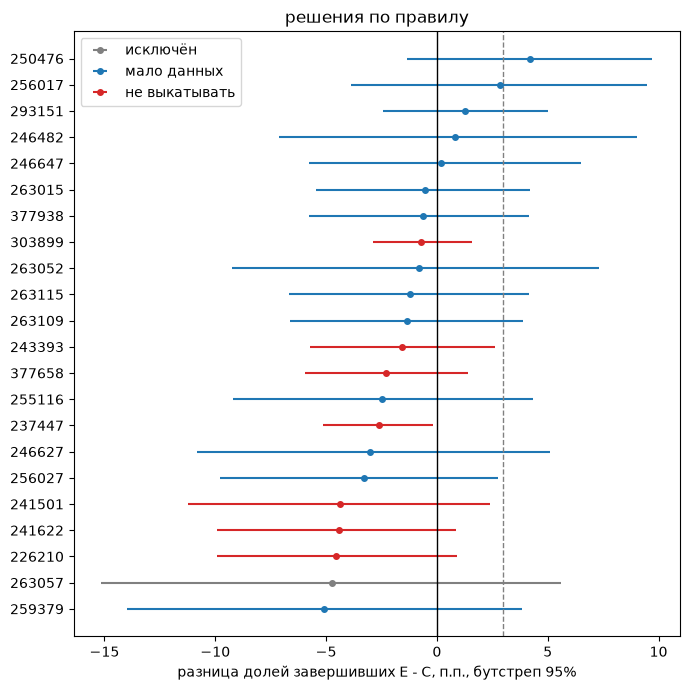

In [6]:
colors = {"выкатывать": "C2", "не выкатывать": "C3", "мало данных": "C0", "исключён": "grey"}
d = table.sort_values("diff").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 7))
for dec, part in d.groupby("decision"):
    ax.errorbar(100 * part["diff"], part.index, xerr=[100 * (part["diff"] - part.boot_lo), 100 * (part.boot_hi - part["diff"])],
                fmt="o", color=colors[dec], label=dec, markersize=4, elinewidth=1.5)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(3, color="grey", linestyle="--", linewidth=1)
ax.set_yticks(d.index, d.experiment_id)
ax.set_xlabel("разница долей завершивших E - C, п.п., бутстреп 95%")
ax.legend(loc="upper left")
ax.set_title("решения по правилу")
plt.tight_layout()

## Итог

- Выкатывать - 0. Ни один эксперимент не показал значимого улучшения доли завершивших, ни до поправки, ни после.
- Не выкатывать - 7: 226210, 237447, 241501, 241622, 243393, 303899, 377658. Во всех эффект незначим, но интервал
  целиком ниже +3 п.п., то есть заметное улучшение исключено. В 237447 интервал целиком ниже нуля (от -5,1 до -0,2),
  но после BH это не значимо.
- Мало данных - 14. Интервалы содержат и ноль, и +3 п.п. Из этапа 4: MDE больше 3 п.п. в 20 экспериментах из 21, так
  что для большинства это ожидаемый исход, а не провал анализа. 256027 сюда попал по правилу устойчивости: в файле он
  был бы «не выкатывать».
- 293151 - «мало данных» по правилу и гипотеза для повторного теста на учениках, у которых срабатывает условие.
- 263057 исключён: группы несравнимы.
- Оговорка к «не выкатывать»: интервалы 95% без поправки на 21 тест. Если все 21 интервал покрывают истину с
  вероятностью 95%, примерно один из них может её не покрыть. Решение «не выкатывать» в 241501 и 243393 держится на
  верхней границе +2,4 и +2,6 п.п., близко к порогу.